# Mosquito sightings vs. West Nile cases: California, 2019-2025

**Question:** do unusual increases in iNaturalist mosquito sightings come before unusual increases in human West Nile virus (WNV) cases?

**Inputs** (run from the repository root):
- `data_ca/inat_mosquito_observations_ca.csv`: one row per mosquito sighting, with counties assigned from coordinates
- `data_ca/inat_all_obs_daily_by_county_ca.csv`: all iNaturalist observations per county-day, used as the activity baseline
- `data_ca/wnv_human_cases.csv`: CDPH human WNV cases by county and week reported

**What this notebook does**
1. Builds a county x CDC week table for 2019-2025.
2. Cleans the case data. Weeks 52 and 53 look like year-end catch-up reporting, so we leave them out of the main analysis.
3. Builds several versions of the mosquito signal: raw sightings, unique observers, with and without heavy posters, Culex only, and without invasive *Aedes*.
4. Removes the normal seasonal pattern from each series, then checks how well sightings line up with cases 0 to 8 weeks later.
5. Repeats the test by season (county-years), which is less noisy than going week by week.
6. Tests the spatial clustering measure from our proposal.

Run it top to bottom. It needs `pandas`, `numpy`, `scipy` and `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date, timedelta
from scipy.stats import spearmanr

START, END = 2019, 2025
LAGS = range(0, 9)                 # weeks between sighting and case report
HEAVY_POSTER_MIN = 50              # users with this many sightings or more (2019-2025) count as heavy posters
EXCLUDE_CASE_WEEKS = {52, 53}      # year-end catch-up reporting

UNITS = {                          # counties with enough sightings, plus one grouped region
    "Los Angeles": ["Los Angeles"],
    "Riverside": ["Riverside"],
    "San Diego": ["San Diego"],
    "Orange": ["Orange"],
    "Sacramento": ["Sacramento"],
    "San Joaquin Valley": ["Fresno", "Kern", "Kings", "Madera", "Merced",
                           "San Joaquin", "Stanislaus", "Tulare"],
}

def mmwr_week(d):
    def week1_start(y):
        jan1 = date(y, 1, 1)
        k = (jan1.weekday() + 1) % 7
        s = jan1 - timedelta(days=k)
        return s + timedelta(days=7) if k > 3 else s
    y = d.year
    if d >= week1_start(y + 1):
        y += 1
    elif d < week1_start(y):
        y -= 1
    return y, (d - week1_start(y)).days // 7 + 1

def week_start(y, w):
    jan1 = date(y, 1, 1)
    k = (jan1.weekday() + 1) % 7
    s = jan1 - timedelta(days=k)
    if k > 3:
        s += timedelta(days=7)
    return pd.Timestamp(s + timedelta(weeks=w - 1))

## 1. Load the data

In [2]:
m = pd.read_csv("data_ca/inat_mosquito_observations_ca.csv")
m["observed_on"] = pd.to_datetime(m["observed_on"], errors="coerce")
m = m.dropna(subset=["observed_on", "county"])
m[["Year", "Week"]] = [mmwr_week(d.date()) for d in m["observed_on"]]
m = m[m.Year.between(START, END)].copy()

user_totals = m.user_id.value_counts()
heavy = set(user_totals[user_totals >= HEAVY_POSTER_MIN].index)
m["heavy_poster"] = m.user_id.isin(heavy)
m["invasive_aedes"] = m.taxon_name.fillna("").str.startswith(("Aedes aegypti", "Aedes albopictus"))

print(f"{len(m):,} sightings, {m.user_id.nunique():,} observers, {m.county.nunique()} counties")
print(f"Heavy posters (>= {HEAVY_POSTER_MIN} sightings): {len(heavy)} users, "
      f"{m.heavy_poster.mean():.0%} of sightings")
print(f"Culex: {m.is_culex.mean():.0%}   invasive Aedes: {m.invasive_aedes.mean():.0%}")

6,586 sightings, 2,733 observers, 58 counties
Heavy posters (>= 50 sightings): 8 users, 16% of sightings
Culex: 18%   invasive Aedes: 15%


In [3]:
base = pd.read_csv("data_ca/inat_all_obs_daily_by_county_ca.csv", parse_dates=["date"])
base[["Year", "Week"]] = [mmwr_week(d.date()) for d in base["date"]]
base = base[base.Year.between(START, END)].groupby(["county", "Year", "Week"]).all_obs.sum()

cases = pd.read_csv("data_ca/wnv_human_cases.csv")
cases.columns = ["Year", "Week", "county", "cases"]
cases = cases[cases.Year.between(START, END)]
print(f"Cases {START}-{END}: {cases.cases.sum():,}; in weeks 52-53: "
      f"{cases[cases.Week.isin(EXCLUDE_CASE_WEEKS)].cases.sum():,} (excluded)")
cases = cases[~cases.Week.isin(EXCLUDE_CASE_WEEKS)].groupby(["county", "Year", "Week"]).cases.sum()

Cases 2019-2025: 1,478; in weeks 52-53: 205 (excluded)


## 2. Versions of the mosquito signal

Each version is calculated per county-week. "Observers" counts each person once per county-week, so one very active user can't inflate the number.

In [4]:
VARIANTS = {
    "sightings":            lambda d: d.groupby(KEYS).size(),
    "observers":            lambda d: d.groupby(KEYS).user_id.nunique(),
    "observers_no_heavy":   lambda d: d[~d.heavy_poster].groupby(KEYS).user_id.nunique(),
    "culex_observers":      lambda d: d[d.is_culex].groupby(KEYS).user_id.nunique(),
    "non_invasive_observers": lambda d: d[~d.invasive_aedes].groupby(KEYS).user_id.nunique(),
}
KEYS = ["county", "Year", "Week"]

weeks = sorted({mmwr_week(date(START, 1, 1) + timedelta(days=i))
                for i in range((date(END, 12, 31) - date(START, 1, 1)).days + 1)})
weeks = [w for w in weeks if START <= w[0] <= END]
counties = sorted(set(base.index.get_level_values(0)))
grid = pd.MultiIndex.from_tuples([(c, y, w) for c in counties for (y, w) in weeks], names=KEYS)

T = pd.DataFrame(index=grid)
T["all_obs"] = base.reindex(grid).fillna(0)
T["cases"] = cases.reindex(grid).fillna(0)
for name, f in VARIANTS.items():
    T[name] = f(m).reindex(grid).fillna(0)
T = T.reset_index()
T["date"] = [week_start(y, w) for y, w in zip(T.Year, T.Week)]
T.head()

,county,Year,Week,all_obs,cases,sightings,observers,observers_no_heavy,culex_observers,non_invasive_observers,date
0,Alameda,2019,1,659.0,0.0,0.0,0.0,0.0,0.0,0.0,2018-12-30
1,Alameda,2019,2,745.0,0.0,0.0,0.0,0.0,0.0,0.0,2019-01-06
2,Alameda,2019,3,678.0,0.0,0.0,0.0,0.0,0.0,0.0,2019-01-13
3,Alameda,2019,4,676.0,0.0,0.0,0.0,0.0,0.0,0.0,2019-01-20
4,Alameda,2019,5,571.0,0.0,0.0,0.0,0.0,0.0,0.0,2019-01-27


## 3. Group into analysis units and remove seasonality

For each unit and series, the **anomaly** is the week's value minus the average for that same week of the year in the *other* years. We leave the current year out of the average so a year can't explain itself. The "per 1k" versions divide by total iNaturalist observations first (per 1,000 observations), which adjusts for iNaturalist's growth and for local bursts like the City Nature Challenge.

In [5]:
SIGNALS = list(VARIANTS)

def unit_table(counties):
    u = T[T.county.isin(counties)].groupby(["Year", "Week", "date"])[["all_obs", "cases"] + SIGNALS].sum().reset_index()
    for s in SIGNALS:
        u[s + "_per1k"] = u[s] / u.all_obs.replace(0, np.nan) * 1000
    return u.sort_values("date").reset_index(drop=True)

def loyo_anomaly(u, col):
    out = pd.Series(np.nan, index=u.index)
    for y in u.Year.unique():
        others = u[u.Year != y].groupby("Week")[col].mean()
        idx = u.Year == y
        out[idx] = u.loc[idx, col] - u.loc[idx, "Week"].map(others)
    return out

U = {}
for name, cs in UNITS.items():
    u = unit_table(cs)
    for col in ["cases"] + SIGNALS + [s + "_per1k" for s in SIGNALS]:
        u[col + "_anom"] = loyo_anomaly(u, col)
    U[name] = u

summary = pd.DataFrame({
    name: {"weeks with any sighting": f"{(u.sightings > 0).mean():.0%}",
           "sightings": int(u.sightings.sum()),
           "cases (excl. wk 52-53)": int(u.cases.sum())}
    for name, u in U.items()}).T
summary

,weeks with any sighting,sightings,cases (excl. wk 52-53)
Los Angeles,83%,1201,226
Riverside,63%,557,45
San Diego,70%,587,9
Orange,43%,362,42
Sacramento,24%,467,60
San Joaquin Valley,41%,270,592


## 4. Weekly timing

This is the Spearman correlation between the sighting anomaly in week *t* and the case anomaly in week *t + lag*. We use Spearman because the counts are small and uneven.

**Caveat:** weekly values tend to follow the week before, so ordinary p-values would make these look stronger than they are. Treat these numbers as descriptive. The shuffle test below and the season-level test in section 5 are better checks.

In [6]:
def lag_corr(u, sig, lag):
    x = u[sig + "_anom"]
    y = u["cases_anom"].shift(-lag)
    ok = x.notna() & y.notna()
    return spearmanr(x[ok], y[ok]).statistic if ok.sum() > 20 else np.nan

rows = []
for name, u in U.items():
    for sig in SIGNALS + [s + "_per1k" for s in SIGNALS]:
        r = {lag: lag_corr(u, sig, lag) for lag in LAGS}
        best = max(r, key=lambda k: abs(r[k]) if pd.notna(r[k]) else -1)
        rows.append({"unit": name, "signal": sig, "best_lag": best, "rho_at_best": r[best],
                     **{f"lag{k}": v for k, v in r.items()}})
L = pd.DataFrame(rows)
L.pivot(index="signal", columns="unit", values="rho_at_best").round(2)

unit,Los Angeles,Orange,Riverside,Sacramento,San Diego,San Joaquin Valley
signal,,,,,,
culex_observers,-0.07,-0.10,0.09,0.27,-0.09,-0.11
culex_observers_per1k,0.09,-0.08,0.17,0.29,-0.10,-0.11
non_invasive_observers,0.10,0.04,0.13,0.13,-0.07,0.10
non_invasive_observers_per1k,0.13,0.09,0.19,0.16,-0.05,0.10
observers,0.12,0.12,0.12,0.14,-0.08,0.08
observers_no_heavy,0.12,0.13,0.18,0.10,-0.08,0.07
observers_no_heavy_per1k,0.15,0.12,0.25,0.14,-0.09,0.09
observers_per1k,0.15,0.15,0.13,0.17,-0.08,0.10
sightings,0.11,0.07,0.12,0.30,-0.08,0.08


In [7]:
L.pivot(index="signal", columns="unit", values="best_lag")

unit,Los Angeles,Orange,Riverside,Sacramento,San Diego,San Joaquin Valley
signal,,,,,,
culex_observers,4,0,7,0,4,8
culex_observers_per1k,3,0,7,0,4,8
non_invasive_observers,2,0,7,0,4,3
non_invasive_observers_per1k,2,0,7,5,1,3
observers,2,8,7,0,1,3
observers_no_heavy,2,8,2,5,1,3
observers_no_heavy_per1k,2,0,7,5,1,0
observers_per1k,2,0,7,5,1,3
sightings,2,5,7,0,1,0


### Year-shuffle test for the main signal

To check whether a correlation could be chance, we shuffle which year's cases line up with which year's sightings, keeping each season intact. Then we recalculate and see how often a shuffled correlation beats the real one.

In [8]:
rng = np.random.default_rng(0)
MAIN = "observers_per1k"

def block_perm_p(u, sig, lag, n=2000):
    real = lag_corr(u, sig, lag)
    years = sorted(u.Year.unique())
    by_year = {y: u[u.Year == y]["cases_anom"].to_numpy() for y in years}
    count = 0
    for _ in range(n):
        perm = rng.permutation(years)
        v = u.copy()
        new = []
        for y, py in zip(years, perm):
            a, b = by_year[y], by_year[py]
            k = min(len(a), len(b))
            new.append(np.concatenate([b[:k], np.full(len(a) - k, np.nan)]))
        v["cases_anom"] = np.concatenate(new)
        if abs(lag_corr(v, sig, lag)) >= abs(real):
            count += 1
    return real, (count + 1) / (n + 1)

perm_rows = []
for name, u in U.items():
    for lag in (2, 4, 6):
        rho, p = block_perm_p(u, MAIN, lag)
        perm_rows.append({"unit": name, "lag": lag, "rho": round(rho, 2), "perm_p": round(p, 3)})
pd.DataFrame(perm_rows).pivot(index="unit", columns="lag", values=["rho", "perm_p"])

rho             perm_p              
lag                    2     4     6      2      4      6
unit                                                     
Los Angeles         0.15  0.08  0.10  0.067  0.205  0.168
Orange              0.08  0.06  0.01  0.368  0.409  0.864
Riverside           0.09  0.07  0.05  0.148  0.178  0.520
Sacramento          0.02  0.13  0.02  0.639  0.129  0.832
San Diego          -0.03 -0.04  0.05  0.589  0.511  0.333
San Joaquin Valley  0.03 -0.01 -0.01  0.642  0.911  0.872

## 5. Season-level test (county-years)

Weekly data is noisy, so this asks a simpler question: in years when a county's **early-season** sightings (May-July) run above its own normal, does it have more cases **later** (August-November)?

Both sides are measured against that county's own average across years, so counties with more people or more WNV don't dominate. We only include counties with at least 30 sightings and 10 cases over the period.

In [9]:
def season(u_counties, sig):
    t = T[T.county.isin(u_counties)].copy()
    t["month"] = t.date.dt.month
    early = t[t.month.between(5, 7)].groupby(["county", "Year"]).agg(s=(sig, "sum"), a=("all_obs", "sum"))
    late = t[t.month.between(8, 11)].groupby(["county", "Year"]).cases.sum()
    d = early.join(late).fillna(0)
    d["rate"] = d.s / d.a.replace(0, np.nan) * 1000
    return d

tot = T.groupby("county")[["sightings", "cases"]].sum()
eligible = tot[(tot.sightings >= 30) & (tot.cases >= 10)].index.tolist()
print("Eligible counties:", eligible)

season_rows = []
for sig in SIGNALS:
    d = season(eligible, sig)
    d["rate_dev"] = d.rate - d.groupby("county").rate.transform("mean")
    d["log_cases_dev"] = np.log1p(d.cases) - d.groupby("county").cases.transform(lambda x: np.log1p(x).mean())
    ok = d.rate_dev.notna()
    rho = spearmanr(d.rate_dev[ok], d.log_cases_dev[ok])
    season_rows.append({"signal": sig, "county_years": int(ok.sum()),
                        "rho": round(rho.statistic, 2), "p": round(rho.pvalue, 3)})
pd.DataFrame(season_rows)

Eligible counties: ['Butte', 'Contra Costa', 'Fresno', 'Kern', 'Los Angeles', 'Merced', 'Orange', 'Placer', 'Riverside', 'Sacramento', 'San Bernardino', 'Shasta', 'Solano', 'Tulare', 'Yolo', 'Yuba']


,signal,county_years,rho,p
0,sightings,112,0.06,0.510
1,observers,112,0.09,0.359
2,observers_no_heavy,112,0.11,0.262
3,culex_observers,112,-0.03,0.791
4,non_invasive_observers,112,0.14,0.147


## 6. Figure: seasonally adjusted signals for Los Angeles and Riverside

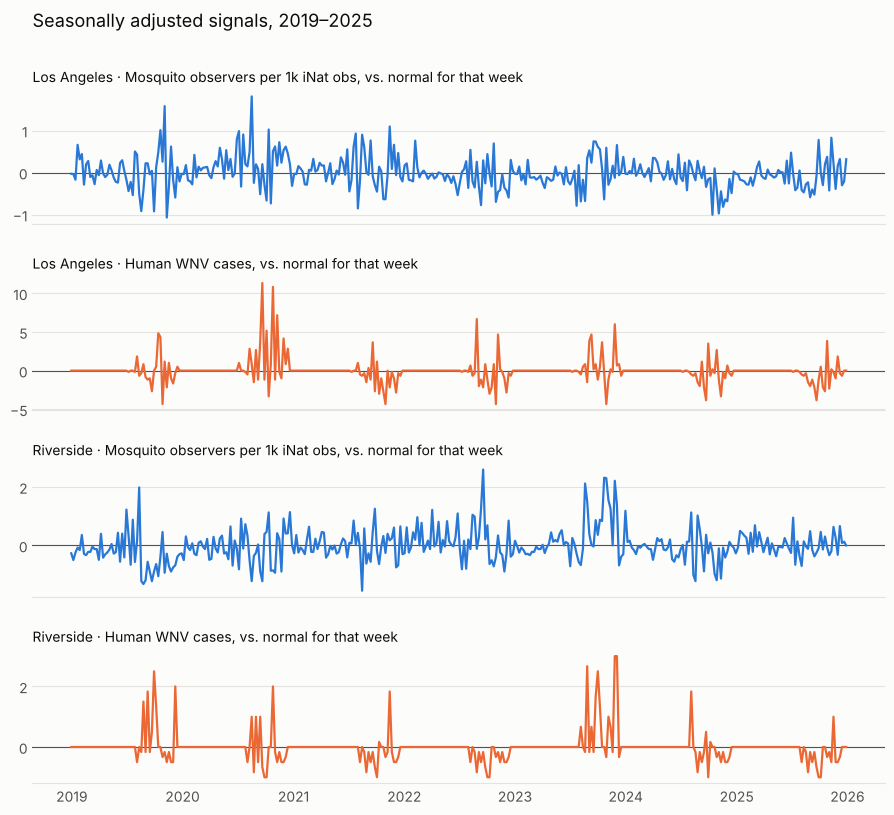

In [10]:
BLUE, ORANGE, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"axes.edgecolor": GRID, "xtick.color": INK2, "ytick.color": INK2})

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True, facecolor=SURF, gridspec_kw={"hspace": 0.4})
for i, name in enumerate(["Los Angeles", "Riverside"]):
    u = U[name]
    for j, (col, colr, lab) in enumerate([
            (MAIN + "_anom", BLUE, "Mosquito observers per 1k iNat obs, vs. normal for that week"),
            ("cases_anom", ORANGE, "Human WNV cases, vs. normal for that week")]):
        ax = axes[2 * i + j]
        ax.set_facecolor(SURF)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.plot(u.date, u[col], color=colr, lw=1.6)
        ax.set_title(f"{name} · {lab}", loc="left", fontsize=10, color=INK)
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        for s in ["top", "right", "left"]:
            ax.spines[s].set_visible(False)
        ax.tick_params(length=0)
fig.suptitle("Seasonally adjusted signals, 2019–2025", x=0.125, ha="left", fontsize=13, color=INK, y=0.97)
fig.savefig("figures/anomalies_la_riverside.png", dpi=150, bbox_inches="tight", facecolor=SURF)
plt.show()

## 7. Spatial clustering

This is the fifth measure from our proposal: are sightings **concentrated in spatial clusters**? The idea is that several different people photographing mosquitoes in the same neighborhood at the same time should be a stronger local signal than the same number of sightings spread across a county.

**Definition.** A sighting counts as *clustered* if at least one **different** person reported a mosquito within `RADIUS_KM` and within 7 days either side. Requiring a different person means one person posting a lot of photos from their backyard, or from a trap, can't create a cluster alone.

**Location quality.** We leave out obscured observations, since iNaturalist moves those coordinates by up to about 20 km, and any with location accuracy worse than 1 km. We keep observations with no accuracy listed, since most phone photos without it are still precise.

Per county-week this gives:
- `clustered_sightings`: sightings that week that are clustered
- `clustered_observers`: unique observers among them
- `cluster_share`: clustered sightings divided by precisely located sightings that week, or how concentrated that week's activity is

In [11]:
from scipy.spatial import cKDTree

RADIUS_KM = 2.0
WINDOW_DAYS = 7

def cluster_flags(df, radius_km=RADIUS_KM, window_days=WINDOW_DAYS):
    # Projected km coordinates (equirectangular; fine at California scale)
    lat0 = np.radians(36.5)
    x = np.radians(df.longitude.to_numpy()) * 6371 * np.cos(lat0)
    y = np.radians(df.latitude.to_numpy()) * 6371
    t = (df.observed_on - pd.Timestamp("2019-01-01")).dt.days.to_numpy()
    users = df.user_id.to_numpy()
    tree = cKDTree(np.column_stack([x, y]))
    flags = np.zeros(len(df), dtype=bool)
    for i, nbrs in enumerate(tree.query_ball_point(np.column_stack([x, y]), r=radius_km)):
        for j in nbrs:
            if j != i and users[j] != users[i] and abs(t[j] - t[i]) <= window_days:
                flags[i] = True
                break
    return flags

precise = m[(m.obscured != True) & ~(m.positional_accuracy > 1000)].copy()
print(f"Precisely located: {len(precise):,} of {len(m):,} sightings ({len(precise)/len(m):.0%})")

for r in (1.0, 2.0, 5.0):
    f = cluster_flags(precise, radius_km=r)
    print(f"  radius {r:>3} km: {f.mean():.1%} of sightings are clustered")

precise["clustered"] = cluster_flags(precise)

Precisely located: 5,427 of 6,586 sightings (82%)
  radius 1.0 km: 6.4% of sightings are clustered
  radius 2.0 km: 8.7% of sightings are clustered


  radius 5.0 km: 16.3% of sightings are clustered


In [12]:
cl = precise[precise.clustered]
T = T.drop(columns=[c for c in ["precise_sightings", "clustered_sightings", "clustered_observers"] if c in T], errors="ignore")
add = pd.DataFrame({
    "precise_sightings": precise.groupby(KEYS).size(),
    "clustered_sightings": cl.groupby(KEYS).size(),
    "clustered_observers": cl.groupby(KEYS).user_id.nunique(),
})
T = T.merge(add, how="left", left_on=KEYS, right_index=True)
T[add.columns] = T[add.columns].fillna(0)

print("Clustered sightings by county (top 10):")
print(T.groupby("county")[["precise_sightings", "clustered_sightings"]].sum()
       .assign(share=lambda d: (d.clustered_sightings / d.precise_sightings).round(2))
       .sort_values("clustered_sightings", ascending=False).head(10))

Clustered sightings by county (top 10):
               precise_sightings  clustered_sightings  share
county                                                      
Santa Clara                349.0                 82.0   0.23
Humboldt                   158.0                 63.0   0.40
Los Angeles                917.0                 53.0   0.06
San Diego                  499.0                 49.0   0.10
Riverside                  483.0                 36.0   0.07
Alameda                    241.0                 24.0   0.10
San Francisco              120.0                 20.0   0.17
San Mateo                  163.0                 19.0   0.12
Nevada                      41.0                 15.0   0.37
Sonoma                     118.0                 13.0   0.11


### Do clusters come before cases?

These are the same tests as before: weekly anomalies at lags of 0 to 8 weeks, the year-shuffle test, and the season-level test.

In [13]:
CL_SIGNALS = ["clustered_sightings", "clustered_observers"]

def unit_table_cl(counties):
    u = T[T.county.isin(counties)].groupby(["Year", "Week", "date"])[
        ["all_obs", "cases", "precise_sightings"] + CL_SIGNALS].sum().reset_index()
    for s in CL_SIGNALS:
        u[s + "_per1k"] = u[s] / u.all_obs.replace(0, np.nan) * 1000
    u["cluster_share"] = u.clustered_sightings / u.precise_sightings.replace(0, np.nan)
    return u.sort_values("date").reset_index(drop=True)

CL_ALL = CL_SIGNALS + [s + "_per1k" for s in CL_SIGNALS] + ["cluster_share"]
UC = {}
for name, cs in UNITS.items():
    u = unit_table_cl(cs)
    u["cluster_share"] = u["cluster_share"].fillna(0)
    for col in ["cases"] + CL_ALL:
        u[col + "_anom"] = loyo_anomaly(u, col)
    UC[name] = u

rows = []
for name, u in UC.items():
    for sig in CL_ALL:
        r = {lag: lag_corr(u, sig, lag) for lag in LAGS}
        best = max(r, key=lambda k: abs(r[k]) if pd.notna(r[k]) else -1)
        n_weeks = int((u.clustered_observers > 0).sum())
        rows.append({"unit": name, "signal": sig, "best_lag": best, "cluster_weeks": n_weeks,
                     # Too few cluster weeks makes a correlation meaningless; blank it out
                     "rho_at_best": r[best] if n_weeks >= 20 else np.nan})
LC = pd.DataFrame(rows)
print("Weeks with at least one cluster, by unit:")
print(LC.groupby("unit").cluster_weeks.first().to_string())
print("\nBest-lag correlation; blank = fewer than 20 cluster weeks (picking the best of 9 lags inflates these)")
LC.pivot(index="signal", columns="unit", values="rho_at_best").round(2)

Weeks with at least one cluster, by unit:
unit
Los Angeles           28
Orange                 2
Riverside             18
Sacramento             3
San Diego             31
San Joaquin Valley     4

Best-lag correlation; blank = fewer than 20 cluster weeks (picking the best of 9 lags inflates these)


unit,Los Angeles,Orange,Riverside,Sacramento,San Diego,San Joaquin Valley
signal,,,,,,
cluster_share,0.11,NaN,NaN,NaN,0.20,NaN
clustered_observers,0.13,NaN,NaN,NaN,0.17,NaN
clustered_observers_per1k,0.14,NaN,NaN,NaN,0.20,NaN
clustered_sightings,0.13,NaN,NaN,NaN,0.16,NaN
clustered_sightings_per1k,0.14,NaN,NaN,NaN,0.20,NaN


In [14]:
perm_rows = []
for name, u in UC.items():
    if (u.clustered_observers > 0).sum() < 20:
        continue
    for lag in (2, 4, 6):
        rho, p = block_perm_p(u, "clustered_observers_per1k", lag)
        perm_rows.append({"unit": name, "lag": lag, "rho": round(rho, 2), "perm_p": round(p, 3)})
pd.DataFrame(perm_rows).pivot(index="unit", columns="lag", values=["rho", "perm_p"])

rho             perm_p              
lag             2     4     6      2      4      6
unit                                              
Los Angeles  0.14 -0.01  0.01  0.124  0.899  0.931
San Diego    0.05  0.20  0.01  0.640  0.126  1.000

In [15]:
season_rows = []
for sig in CL_SIGNALS:
    d = season(eligible, sig)
    d["rate_dev"] = d.rate - d.groupby("county").rate.transform("mean")
    d["log_cases_dev"] = np.log1p(d.cases) - d.groupby("county").cases.transform(lambda x: np.log1p(x).mean())
    ok = d.rate_dev.notna()
    rho = spearmanr(d.rate_dev[ok], d.log_cases_dev[ok])
    season_rows.append({"signal": sig, "county_years": int(ok.sum()),
                        "rho": round(rho.statistic, 2), "p": round(rho.pvalue, 3)})
pd.DataFrame(season_rows)

,signal,county_years,rho,p
0,clustered_sightings,112,0.1,0.305
1,clustered_observers,112,0.1,0.305


## 8. Notes for interpretation

**Week reported is not onset.** CDPH weeks are when a case was reported, which usually comes a week or more after symptoms start and later still after infection. That's why best lags of 4 to 8 weeks are plausible.

**The species mix differs by place.** Invasive *Aedes* make up a large share of Southern California sightings, and they aren't the main WNV carriers. The `culex_observers` and `non_invasive_observers` versions test whether removing them helps.

**Heavy posters.** A handful of users, possibly uploading trap catches, can create large spikes. `observers` counts each person once per county-week, and `observers_no_heavy` leaves them out entirely.

**Small numbers.** Seven seasons is a short record. A weak result here shows the limits of this signal, but it doesn't prove there's no signal at all.